# Práctica: Implementación y Análisis de un Sistema de Recomendación Basado en Modelos (SVD)

**Asignatura:** Gestión de la Información  
**Grupo de prácticas:** Grupo 12 (Adrián Bello Sánchez y Alberto Cuervo Prieto)  
**Dataset:** MovieLens 100k (`ml-latest-small`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from surprise import Reader, Dataset, SVD
from surprise.model_selection import GridSearchCV
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

## 1. Implementación básica del filtro colaborativo (SVD con Grid Search y CV)

In [2]:
ratings = pd.read_csv('ratings.csv')
movies = pd.read_csv('movies.csv')

reader = Reader(rating_scale=(0.5, 5.0))
data = Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)

param_grid = {
    'n_factors': [20, 50, 100],
    'n_epochs': [20, 30],
    'lr_all': [0.005, 0.01],
    'reg_all': [0.05, 0.1]
}

gs = GridSearchCV(SVD, param_grid, measures=['RMSE', 'MAE'], cv=3, n_jobs=-1)
gs.fit(data)

print(f"Mejor RMSE: {gs.best_score['rmse']:.4f}")
print(f"Mejor MAE:  {gs.best_score['mae']:.4f}")
print('\nMejores hiperparámetros:')
for param, valor in gs.best_params['rmse'].items():
    print(f"  - {param}: {valor}")

params = gs.best_params['rmse']
modelo = SVD(n_factors=params['n_factors'], n_epochs=params['n_epochs'],
             lr_all=params['lr_all'], reg_all=params['reg_all'], random_state=42)

Mejor RMSE: 0.8628
Mejor MAE:  0.6625

Mejores hiperparámetros:
  - n_factors: 100
  - n_epochs: 30
  - lr_all: 0.01
  - reg_all: 0.1


## 2. Añadir usuarios del equipo y Top 10 recomendaciones

In [3]:
adrian_ratings = [
    {'userId': 9991, 'movieId': 2571, 'rating': 5.0},   # Matrix
    {'userId': 9991, 'movieId': 79132, 'rating': 5.0},  # Inception
    {'userId': 9991, 'movieId': 109487, 'rating': 5.0}, # Interstellar
    {'userId': 9991, 'movieId': 296, 'rating': 4.5},    # Pulp Fiction
    {'userId': 9991, 'movieId': 589, 'rating': 4.5},    # Terminator 2
    {'userId': 9991, 'movieId': 260, 'rating': 5.0},    # Star Wars IV
    {'userId': 9991, 'movieId': 1196, 'rating': 5.0},   # Star Wars V
    {'userId': 9991, 'movieId': 367, 'rating': 1.5},    # The Mask
    {'userId': 9991, 'movieId': 357, 'rating': 1.5},    # Four Weddings
    {'userId': 9991, 'movieId': 597, 'rating': 1.0},    # Pretty Woman
]

alberto_ratings = [
    {'userId': 9992, 'movieId': 1, 'rating': 5.0},      # Toy Story
    {'userId': 9992, 'movieId': 3114, 'rating': 5.0},   # Toy Story 2
    {'userId': 9992, 'movieId': 78499, 'rating': 5.0},  # Toy Story 3
    {'userId': 9992, 'movieId': 364, 'rating': 5.0},    # The Lion King
    {'userId': 9992, 'movieId': 595, 'rating': 4.5},    # Beauty and the Beast
    {'userId': 9992, 'movieId': 588, 'rating': 4.5},    # Aladdin
    {'userId': 9992, 'movieId': 6377, 'rating': 5.0},   # Finding Nemo
    {'userId': 9992, 'movieId': 589, 'rating': 1.0},    # Terminator 2
    {'userId': 9992, 'movieId': 1258, 'rating': 1.5},   # The Shining
]

df_equipo = pd.DataFrame(adrian_ratings + alberto_ratings)
ratings_ampliado = pd.concat([ratings[['userId', 'movieId', 'rating']], df_equipo], ignore_index=True)

data_ampliada = Dataset.load_from_df(ratings_ampliado, reader)
trainset = data_ampliada.build_full_trainset()
modelo.fit(trainset)

def recomendar_top_10(user_id, min_votos=20):
    vistas = set(ratings_ampliado[ratings_ampliado['userId'] == user_id]['movieId'])
    conteo_votos = ratings_ampliado['movieId'].value_counts()
    candidatas = conteo_votos[conteo_votos >= min_votos].index
    
    predicciones = []
    for mid in candidatas:
        if mid not in vistas:
            pred = modelo.predict(user_id, mid).est
            predicciones.append((mid, pred))
    
    predicciones.sort(key=lambda x: x[1], reverse=True)
    
    resultado = []
    for rank, (mid, nota) in enumerate(predicciones[:10], 1):
        info = movies[movies['movieId'] == mid].iloc[0]
        resultado.append({
            'Ranking': f"#{rank}",
            'Título': info['title'],
            'Géneros': info['genres'],
            'Predicción': round(nota, 2)
        })
    return pd.DataFrame(resultado)

print("=== TOP 10 RECOMENDACIONES: ADRIÁN (userId 9991) ===")
print(recomendar_top_10(9991).to_string(index=False))

print("\n=== TOP 10 RECOMENDACIONES: ALBERTO (userId 9992) ===")
print(recomendar_top_10(9992).to_string(index=False))

=== TOP 10 RECOMENDACIONES: ADRIÁN (userId 9991) ===
Ranking                                                                      Título                Géneros  Predicción
     #1                                                       Godfather, The (1972)            Crime|Drama        4.56
     #2 Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964)             Comedy|War        4.44
     #3                                                  Usual Suspects, The (1995) Crime|Mystery|Thriller        4.39
     #4                                            Shawshank Redemption, The (1994)            Crime|Drama        4.37
     #5                   Lord of the Rings: The Fellowship of the Ring, The (2001)      Adventure|Fantasy        4.36
     #6                                                    On the Waterfront (1954)            Crime|Drama        4.35
     #7                                        Bridge on the River Kwai, The (1957)    Adventure|Drama|War        

## 3. Análisis de sesgos estimados en el modelo

--- USUARIOS QUE TIENDEN A PUNTUAR MÁS ALTO (Top 5) ---
 userId  sesgo_bu  nota_media
     53    1.2684        5.00
     43    1.0922        4.55
    452    0.9195        4.56
    276    0.9160        4.39
     12    0.8849        4.39

--- USUARIOS QUE TIENDEN A PUNTUAR MÁS BAJO (Top 5) ---
 userId  sesgo_bu  nota_media
    442   -1.9251        1.27
    153   -1.2985        2.22
    139   -1.2653        2.14
    508   -1.2504        2.15
    567   -1.1985        2.25

--- PELÍCULAS CON MAYOR NÚMERO DE RATINGS ---
 movieId                                    titulo  num_ratings  nota_media  sesgo_bi
     356                       Forrest Gump (1994)          329        4.16    0.5864
     318          Shawshank Redemption, The (1994)          317        4.43    0.8171
     296                       Pulp Fiction (1994)          308        4.20    0.6748
     593          Silence of the Lambs, The (1991)          279        4.16    0.5974
    2571                        Matrix, The (1999)

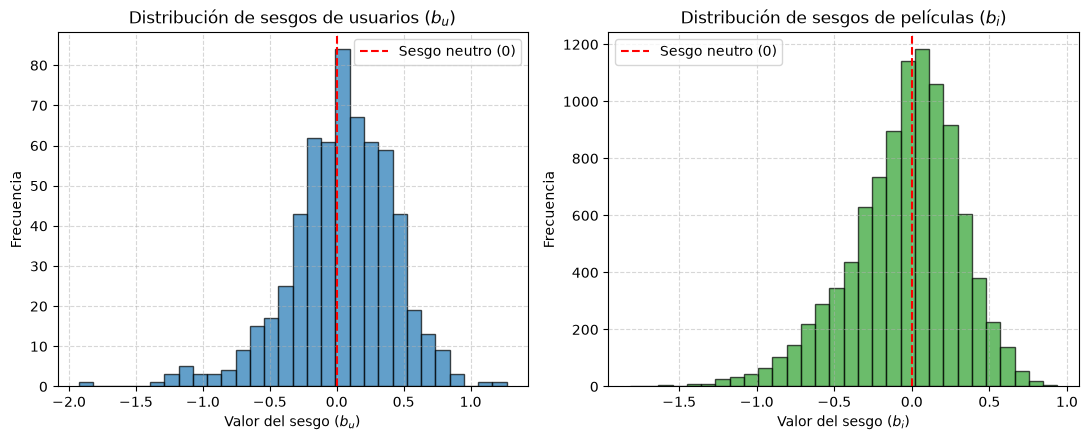

In [4]:
sesgos_u = []
for inner_u, b in enumerate(modelo.bu):
    uid = trainset.to_raw_uid(inner_u)
    media_real = ratings_ampliado[ratings_ampliado['userId'] == uid]['rating'].mean()
    sesgos_u.append({'userId': uid, 'sesgo_bu': round(b, 4), 'nota_media': round(media_real, 2)})

df_sesgos_u = pd.DataFrame(sesgos_u)

print("--- USUARIOS QUE TIENDEN A PUNTUAR MÁS ALTO (Top 5) ---")
print(df_sesgos_u.sort_values(by='sesgo_bu', ascending=False).head(5).to_string(index=False))

print("\n--- USUARIOS QUE TIENDEN A PUNTUAR MÁS BAJO (Top 5) ---")
print(df_sesgos_u.sort_values(by='sesgo_bu', ascending=True).head(5).to_string(index=False))

top_votadas = ratings_ampliado['movieId'].value_counts().head(10).reset_index()
top_votadas.columns = ['movieId', 'num_ratings']
top_votadas['titulo'] = top_votadas['movieId'].apply(lambda x: movies[movies['movieId'] == x]['title'].values[0])
top_votadas['nota_media'] = top_votadas['movieId'].apply(lambda x: round(ratings_ampliado[ratings_ampliado['movieId'] == x]['rating'].mean(), 2))
top_votadas['sesgo_bi'] = top_votadas['movieId'].apply(lambda x: round(modelo.bi[trainset.to_inner_iid(x)], 4))

print("\n--- PELÍCULAS CON MAYOR NÚMERO DE RATINGS ---")
print(top_votadas[['movieId', 'titulo', 'num_ratings', 'nota_media', 'sesgo_bi']].to_string(index=False))

# Histograma de sesgos de usuarios y películas
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(modelo.bu, bins=30, color='#1f77b4', edgecolor='black', alpha=0.7)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Sesgo neutro (0)')
axes[0].set_title('Distribución de sesgos de usuarios ($b_u$)')
axes[0].set_xlabel('Valor del sesgo ($b_u$)')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].hist(modelo.bi, bins=30, color='#2ca02c', edgecolor='black', alpha=0.7)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Sesgo neutro (0)')
axes[1].set_title('Distribución de sesgos de películas ($b_i$)')
axes[1].set_xlabel('Valor del sesgo ($b_i$)')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('sesgos_distribucion.png', dpi=300)
plt.show()

## 4. Análisis en el espacio latente: Películas más próximas a 'Toy Story'

In [5]:
toy_story_id = 1
toy_story_inner = trainset.to_inner_iid(toy_story_id)
vec_toy_story = modelo.qi[toy_story_inner].reshape(1, -1)

similitudes = cosine_similarity(vec_toy_story, modelo.qi)[0]
indices_ordenados = np.argsort(similitudes)[::-1]

conteo_votos = ratings_ampliado['movieId'].value_counts()
similares = []

for idx in indices_ordenados:
    mid = trainset.to_raw_iid(idx)
    if mid != toy_story_id and conteo_votos.get(mid, 0) >= 20:
        info = movies[movies['movieId'] == mid].iloc[0]
        similares.append({
            'Título': info['title'],
            'Géneros': info['genres'],
            'Similitud': round(similitudes[idx], 3),
            'Votos': conteo_votos[mid]
        })
    if len(similares) == 10:
        break

print("Top 10 películas más próximas a 'Toy Story (1995)' en el espacio latente:")
print(pd.DataFrame(similares).to_string(index=False))

Top 10 películas más próximas a 'Toy Story (1995)' en el espacio latente:
                                             Título                                          Géneros  Similitud  Votos
                                     Aladdin (1992)      Adventure|Animation|Children|Comedy|Musical      0.653    184
                                 Toy Story 2 (1999)      Adventure|Animation|Children|Comedy|Fantasy      0.589     98
        Wallace & Gromit: The Wrong Trousers (1993)                  Animation|Children|Comedy|Crime      0.559     56
                                Finding Nemo (2003)              Adventure|Animation|Children|Comedy      0.532    142
                              101 Dalmatians (1996)                        Adventure|Children|Comedy      0.512     47
                                 Toy Story 3 (2010) Adventure|Animation|Children|Comedy|Fantasy|IMAX      0.501     56
Harry Potter and the Deathly Hallows: Part 2 (2011)      Action|Adventure|Drama|Fantasy|Myste